# 01_Exploration du dataset : 
---
## Entrepôt d'un fabricant de chaussures

Objectif : comprendre la structure de l'entrepôt et du stock, pour construire le monde de simulation et la base de stock du robot d'inventaire.

**Source** : R. Furlan de Assis, W. de Paula Ferreira, M. Ouhimmou, *Order picking dataset from a warehouse of a footwear manufacturing company*, Data in Brief 61 (2025), 111837, doi:10.1016/j.dib.2025.111837. Données : Mendeley Data, doi:10.17632/pf2w725pw3.1.

**Licence** : CC BY 4.0. Les données brutes ne sont pas modifiées ; les transformations sont faites dans ce notebook.

### 1. Chargement

In [18]:
from pathlib import Path
import ast

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


RAW = Path("../data/raw/footwear_warehouse")

### 2. Emplacements

#### 2.1 Aperçu du fichier


In [19]:
loc = pd.read_csv(RAW / "Storage_Location.csv")

print("Nbre de lignes :", loc.shape[0])
print("Nbre de colonnes :", loc.shape[1])

loc.head()

Nbre de lignes : 2292
Nbre de colonnes : 5


,originalLocation,position,x,y,z
0,A-14-11,"368, 0, 1",368,0,1
1,A-14-12,"352, 0, 1",352,0,1
2,A-14-13,"336, 0, 1",336,0,1
3,A-14-21,"368, 0, 2",368,0,2
4,A-14-22,"352, 0, 2",352,0,2


#### 2.2 Dimensions et niveaux

In [20]:
print("Etendue des coordonnées :")
loc[["x", "y", "z"]].describe()

Etendue des coordonnées :


,x,y,z
count,2292.000000,2292.000000,2292.000000
mean,331.230366,835.895288,2.023124
std,170.270238,416.452147,1.011021
min,86.000000,0.000000,1.000000
25%,186.000000,482.000000,1.000000
50%,302.000000,900.000000,2.000000
75%,484.000000,1170.000000,3.000000
max,666.000000,1440.000000,4.000000


In [21]:
print("hauteurs distinctes: ")
loc["z"].value_counts().sort_index()

hauteurs distinctes: 


z
1    846
2    846
3    301
4    299
Name: count, dtype: int64

#### 2.3 Échelle de l'entrepôt

In [22]:
# ecarts entre coordonnees successives, pour retrouver l'echelle
xs = np.sort(loc["x"].unique())
ys = np.sort(loc["y"].unique())

print("x distincts :", xs)
print("ecarts x :", np.diff(xs))
print("y distincts :", ys)
print("ecarts y :", np.diff(ys))

x distincts : [ 86 102 118 136 152 168 186 202 218 236 252 268 286 302 318 336 352 368
 403 434 450 466 484 500 516 534 550 566 584 600 616 634 650 666]
ecarts x : [16 16 18 16 16 18 16 16 18 16 16 18 16 16 18 16 16 35 31 16 16 18 16 16
 18 16 16 18 16 16 18 16 16]
y distincts : [   0   32   90  122  180  212  270  302  360  392  450  482  540  572
  688  720  778  810  868  900  958  990 1048 1080 1138 1170 1228 1260
 1318 1350 1408 1440]
ecarts y : [ 32  58  32  58  32  58  32  58  32  58  32  58  32 116  32  58  32  58
  32  58  32  58  32  58  32  58  32  58  32  58  32]


#### 2.4 Position des allées

In [23]:
pts = pd.read_csv(RAW /"Support_Points_Navigation.csv", sep=";")
pts.head()

,points_specified,labels
0,"(66.0, -29.0, 1.0)",LC-01
1,"(66.0, 61.0, 1.0)",LC-02
2,"(66.0, 151.0, 1.0)",LC-03
3,"(66.0, 241.0, 1.0)",LC-04
4,"(66.0, 331.0, 1.0)",LC-05


In [24]:
# "(x, y, z)" en texte -> trois colonnes, literal_eval plus sur que eval
pts[["x", "y", "z"]] = pts["points_specified"].apply(ast.literal_eval).apply(pd.Series)

print(len(pts), "points")
print("x des points :", np.sort(pts["x"].unique()))
print("y des points :", np.sort(pts["y"].unique()))

44 points
x des points : [ 66. 403. 686.]
y des points : [ -29.   61.  151.  241.  331.  421.  511.  631.  751.  841.  931. 1021.
 1111. 1201. 1291. 1381. 1471.]


#### 2.5 Vérification visuelle du plan

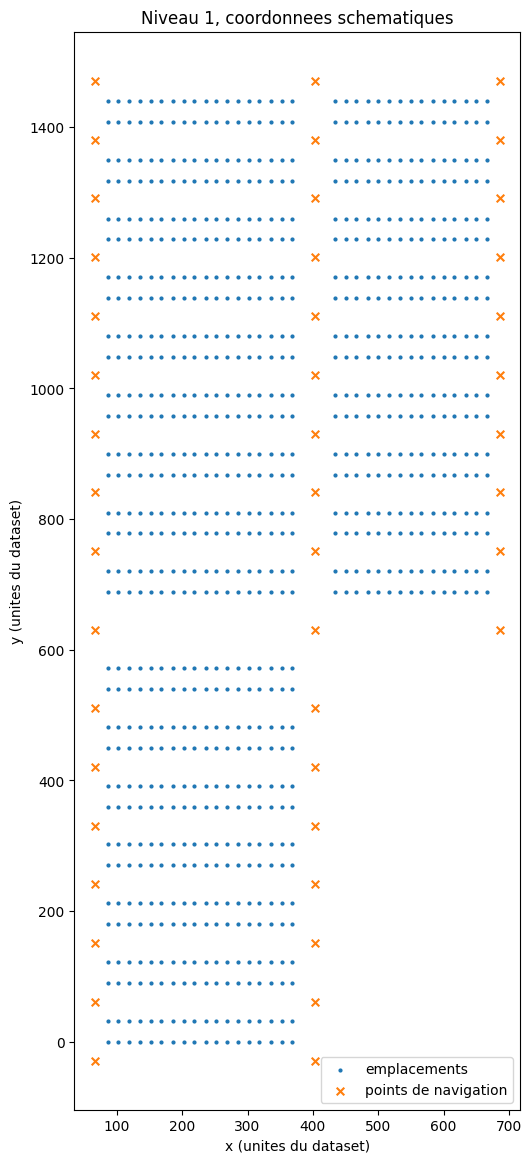

In [25]:
niv1 = loc[loc["z"] == 1]

fig, ax = plt.subplots(figsize=(8, 14))
ax.scatter(niv1["x"], niv1["y"], s=4, label="emplacements")
ax.scatter(pts["x"], pts["y"], s=30, marker="x", label="points de navigation")
ax.set_xlabel("x (unites du dataset)")
ax.set_ylabel("y (unites du dataset)")
ax.set_aspect("equal")
ax.legend()
ax.set_title("Niveau 1, coordonnees schematiques")
plt.show()

#### 2.6 Dimensions réelles d'après le plan DWG

In [26]:
IN = 0.0254  # 1 pouce en metres

# cotes relevees sur Full layout.dwg, en pouces
dwg = pd.Series({
    "troncon": 144.125,
    "position": 47.25,
    "profondeur_rayonnage": 60,
    "allee": 58,
    "allee_centrale": 116,
    "allee_transversale": 154,
})

# hauteur des lisses par niveau, en pouces
lisses = pd.Series({1: 9, 2: 54, 3: 99, 4: 174})

dwg.mul(IN).round(2), lisses.mul(IN).round(2)

(troncon                 3.66
 position                1.20
 profondeur_rayonnage    1.52
 allee                   1.47
 allee_centrale          2.95
 allee_transversale      3.91
 dtype: float64,
 1    0.23
 2    1.37
 3    2.51
 4    4.42
 dtype: float64)

In [27]:
print(7 * dwg["profondeur_rayonnage"] + 6 * dwg["allee"], "pouces, 768 attendus (bloc bas)")
print(9 * dwg["profondeur_rayonnage"] + 8 * dwg["allee"], "pouces, 1004 attendus (bloc haut)")

# facteur pouces / unite du dataset, different selon l'axe
print("x :", dwg["troncon"] / 48)
print("y :", (dwg["profondeur_rayonnage"] + dwg["allee"]) / 90)

768.0 pouces, 768 attendus (bloc bas)
1004.0 pouces, 1004 attendus (bloc haut)
x : 3.0026041666666665
y : 1.3111111111111111


**Conclusions sur les emplacements**

- 2 292 emplacements (2 293 annoncés), sur *4 niveaux* : `z` est un numéro de niveau.
- Niveaux 1 et 2 : 3 positions par tronçon ; niveaux 3 et 4 : un seul emplacement par tronçon.
- *Identifiant* : zone, tronçon, puis niveau et position (`A-14-21` = zone A, tronçon 14, niveau 2, position 1).
- Les coordonnées du dataset sont **schématiques** : facteurs d'échelle différents en x (≈ 3 pouces/unité) et en y (≈ 1,31 pouce/unité). *La géométrie réelle vient du plan DWG*.
- *Dimensions réelles* : tronçons de 3.66 m, rayonnages de 1.52 m de profondeur accessibles des deux côtés, **allées de 1.47 m**, allée centrale de 2.95 m, allée transversale de 3.91 m.
- Étiquettes sur les lisses à 0.23 m, 1.37 m, 2.51 m et 4.42 m ; cartons jusqu'à 6.10 m

### 3. Stock

#### 3.1 Aperçu du fichier

In [29]:
stock = pd.read_csv(RAW / "Random_Storage.csv")

print(stock.shape)
stock.head()

(2292, 19)


,originalLocation,col_1,col_2,col_3,col_4,col_5,col_6,col_7,col_8,col_9,col_10,col_11,col_12,col_13,col_14,col_15,col_16,col_17,col_18
0,A-14-11,TQBVRI;7,O7TSVL;12,4E0KXI;16,ULG3QT;11,AKP0A7;9,CD1NU9;7,A7MDBC;15,0SJH1Z;16,XFQ9CP;7,05W6TK;13,YXGRMP;9,VWXLZJ;16,TLFT43;8,PY5UPB;11,H51IVV;10,K3YA1X;11,2T1DJM;13,NISP6K;14
1,A-14-12,YE890X;5,TLFT43;10,EYEOXS;6,QP56BU;12,VWXLZJ;5,6NDM0O;10,A19092;14,YF0X2Z;16,FQ53YY;14,YRRNGL;15,JHSQHS;6,TLFT43;14,WRRW1W;6,TBCCF7;11,SVFO5S;10,TB6WIP;9,8N10W9;7,YRRNGL;8
2,A-14-13,M8W7TS;12,63KAC1;10,GPBMZJ;9,CVU3QV;11,05W6TK;14,A19092;4,TBCCF7;9,ZGYCSW;13,AHR20O;4,8N10W9;7,TBCCF7;15,9VBE59;11,IA7X1P;15,63KAC1;10,I2B1FH;9,O9YFO8;10,V7JUQL;13,N6JU7C;13
3,A-14-21,CST1KC;5,O7TSVL;14,HGXJD0;10,37VA62;13,AHSNWF;13,9KHDG3;8,5P4LRT;12,FQ53YY;14,QVFB0Q;4,J3FI7N;11,X31OGS;13,HOUGRO;13,VHQ356;7,EAJXUV;8,JU0ODD;12,SWN7AU;4,IYLV38;9,QVFB0Q;7
4,A-14-22,5IXVJ1;13,ZX6MUV;5,NM6C73;11,I2B1FH;16,0LNUOV;11,F29V5I;7,QTMT7N;13,SMMRK3;6,QVFB0Q;8,W518XY;9,ZRCYSH;6,6WT73N;11,EO69NY;11,PZUF7K;4,QP56BU;6,O9YFO8;14,CST1KC;12,6M2FJM;10


#### 3.2 Passage au format long

In [32]:
cols = [f"col_{i}" for i in range(1, 19)]

long = stock.melt(id_vars="originalLocation", value_vars=cols,
                  var_name="case", value_name="contenu")
long = long.dropna(subset=["contenu"])

long[["produit", "quantite"]] = long["contenu"].str.split(";", expand=True)
long["quantite"] = long["quantite"].astype(float).astype(int)
long = long.drop(columns="contenu")

print(long.shape)
long.head()

(41256, 4)


,originalLocation,case,produit,quantite
0,A-14-11,col_1,TQBVRI,7
1,A-14-12,col_1,YE890X,5
2,A-14-13,col_1,M8W7TS,12
3,A-14-21,col_1,CST1KC,5
4,A-14-22,col_1,5IXVJ1,13


#### 3.3 Contenu du stock

In [33]:
print("emplacements :", long["originalLocation"].nunique())
print("produits distincts :", long["produit"].nunique())

# emplacements du stock qui n'existent pas dans le plan
absents = set(long["originalLocation"]) - set(loc["originalLocation"])
print("emplacements absents du plan :", len(absents))

# meme produit plusieurs fois dans un meme emplacement
doublons = long.duplicated(subset=["originalLocation", "produit"], keep=False)
print("lignes en doublon :", doublons.sum())

emplacements : 2292
produits distincts : 208
emplacements absents du plan : 0
lignes en doublon : 23125


In [34]:
# nb de produits par emplacement, puis quantites
print(long.groupby("originalLocation").size().describe())
long["quantite"].describe()

count    2292.0
mean       18.0
std         0.0
min        18.0
25%        18.0
50%        18.0
75%        18.0
max        18.0
dtype: float64


count    41256.000000
mean        10.249612
std         13.175216
min          4.000000
25%          7.000000
50%          9.000000
75%         12.000000
max        280.000000
Name: quantite, dtype: float64

#### 3.4 Base de stock agrégée

In [38]:
# (emplacement, produit), quantites ignorees
base = long.drop_duplicates(subset=["originalLocation", "produit"])[["originalLocation", "produit"]]

print(base.shape)
print(base.groupby("originalLocation").size().describe())
base.head()

(20097, 2)
count    2292.000000
mean        8.768325
std         8.156693
min         1.000000
25%         1.000000
50%         1.000000
75%        17.000000
max        18.000000
dtype: float64


,originalLocation,produit
0,A-14-11,TQBVRI
1,A-14-12,YE890X
2,A-14-13,M8W7TS
3,A-14-21,CST1KC
4,A-14-22,5IXVJ1


In [37]:
# valeurs extremes de quantite
long.nlargest(5, "quantite")

,originalLocation,case,produit,quantite
2203,Q-23-21,col_1,PY5UPB,280
4495,Q-23-21,col_2,PY5UPB,280
6787,Q-23-21,col_3,PY5UPB,280
9079,Q-23-21,col_4,PY5UPB,280
11371,Q-23-21,col_5,PY5UPB,280


**Conclusions sur le stock**

- 2 292 emplacements, tous présents dans le plan, tous remplis avec exactement 18 entrées : aucun emplacement vide dans les données.
- 208 produits distincts, répartis dans tout l'entrepôt (stockage aléatoire).
- Deux types d'emplacements : au moins la moitié ne contiennent qu'un seul produit, recopié dans les 18 cases ; les autres contiennent 17 ou 18 produits différents.
- Les doublons sont un remplissage artificiel, pas des pointures : un même produit apparaît avec la même quantité dans chaque case (par exemple `PY5UPB`, 280 unités, 18 fois dans `Q-23-21`). Les quantités ne sont donc pas fiables.
- Base du robot : 20 097 couples (emplacement, produit), sans quantité, cohérent avec un robot qui vérifie la présence et la position.
- Les emplacements vides et les erreurs seront introduits volontairement pour tester le robot.

### 4. Produits

#### 4.1 Aperçu du fichier

In [41]:
prod = pd.read_csv(RAW / "Product.csv", sep=";")

print(prod.shape)
prod.head()

(208, 3)


,Reference,ABCCOD,Sector
0,O9YFO8,A,PF
1,I1X92B,A,PF
2,HOUGRO,B,PF
3,D05ZS7,A,PF
4,XSFSKX,C,PF


#### 4.2 Lien avec le stock

In [42]:
print("references :", prod["Reference"].nunique(), "pour", len(prod), "lignes")

# les codes du stock doivent exister dans le fichier produits
codes_stock = set(base["produit"])
codes_prod = set(prod["Reference"])
print("codes du stock absents de Product :", len(codes_stock - codes_prod))
print("references de Product absentes du stock :", len(codes_prod - codes_stock))

references : 208 pour 208 lignes
codes du stock absents de Product : 0
references de Product absentes du stock : 0


In [43]:
# repartition par classe et par secteur
print(prod["ABCCOD"].value_counts())
print(prod["Sector"].value_counts())

ABCCOD
C    94
B    70
A    44
Name: count, dtype: int64
Sector
PF          208
Name: count, dtype: int64


**Conclusions sur les produits**

- 208 références, une ligne chacune, toutes présentes dans le stock et inversement : référentiel cohérent.
- Aucune information de pointure : confirme que les doublons du stock sont un remplissage artificiel.
- Classe ABC : 44 produits A, 70 B, 94 C. Secteur unique (`PF`), sans intérêt pour l'analyse.
- Aucune référence inconnue dans les données : ce cas sera testé par des erreurs introduites.

## 5. Conclusions pour le robot

- **Géométrie** : les coordonnées du dataset sont schématiques. Le monde de simulation sera construit avec les cotes réelles du plan DWG et la disposition du dataset.
- **Allées étroites** : 17 allées parallèles de 1,47 m, une allée centrale de 2,95 m, des allées transversales de 3,91 m. 
- **Hauteur** : étiquettes sur les lisses à 0,23 m, 1,37 m, 2,51 m et 4,42 m ; le robot doit lire jusqu'à environ 4,5 m.
- **Volume** : 2 292 emplacements et 20 097 couples (emplacement, produit), jusqu'à 18 références par emplacement.
- **Navigation** : les 44 points de navigation forment le réseau d'allées, base pour placer les arrêts du robot.
- **Base de stock** : couples (emplacement, produit) sans quantité ; emplacements vides et erreurs à introduire volontairement.